In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

PROJECT_DIR = Path(r"D:\AI-MSU")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

pred = pd.read_csv(PROCESSED_DIR / "isolation_forest_baseline.csv", parse_dates=["day"])
answer_files = list(RAW_DIR.rglob("insiders.csv"))
if not answer_files:
    raise FileNotFoundError("insiders.csv not found")
gt = pd.read_csv(answer_files[0])

gt["dataset"] = gt["dataset"].astype(str)
gt42 = gt[gt["dataset"].str.contains(r"4\.2", regex=True, na=False)].copy()
gt42["start"] = pd.to_datetime(gt42["start"], errors="coerce")
gt42["end"] = pd.to_datetime(gt42["end"], errors="coerce")
print("Known incidents in r4.2:", len(gt42))
print("Known insider users:", gt42["user"].nunique())

Known incidents in r4.2: 70
Known insider users: 70


In [2]:
known_users = set(gt42["user"].dropna())
flagged_users = set(pred.loc[pred["is_anomaly"], "user"].dropna())
all_users = sorted(set(pred["user"].dropna()))

actual = [1 if user in known_users else 0 for user in all_users]
predicted = [1 if user in flagged_users else 0 for user in all_users]

matrix = confusion_matrix(actual, predicted, labels=[0, 1])
print("Known insider users flagged:", len(known_users & flagged_users))
print("Insider user recall:", round(len(known_users & flagged_users) / len(known_users), 4))
print("Share of flagged users that are known insiders:", round(len(known_users & flagged_users) / len(flagged_users), 4))

display(pd.DataFrame(matrix, index=["Not labelled insider", "Known insider"],
                     columns=["Not flagged", "Flagged"]))

Known insider users flagged: 51
Insider user recall: 0.7286
Share of flagged users that are known insiders: 0.2982


,Not flagged,Flagged
Not labelled insider,810,120
Known insider,19,51


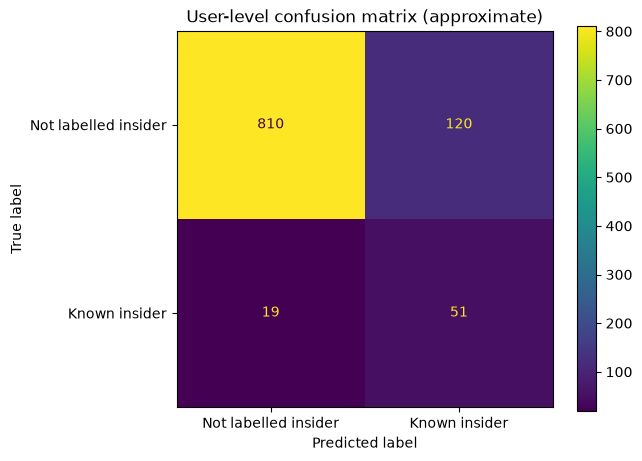

In [3]:
cm_display = ConfusionMatrixDisplay(confusion_matrix=matrix,
                                   display_labels=["Not labelled insider", "Known insider"])
cm_display.plot(values_format="d")
plt.title("User-level confusion matrix (approximate)")
plt.tight_layout()
plt.show()

In [4]:
incident_rows = []
for row in gt42.itertuples(index=False):
    matched = pred[
        (pred["user"] == row.user) &
        (pred["day"] >= row.start.normalize()) &
        (pred["day"] <= row.end.normalize())
    ]
    incident_rows.append({
        "scenario": row.scenario,
        "user": row.user,
        "detected": bool(matched["is_anomaly"].any()),
        "days_in_window": len(matched)
    })

incidents = pd.DataFrame(incident_rows)
print("Incidents detected:", int(incidents["detected"].sum()), "out of", len(incidents))
print("Incident-window recall:", round(incidents["detected"].mean(), 4))
display(incidents.groupby("scenario")["detected"].agg(["sum", "count", "mean"]))

Incidents detected: 31 out of 70
Incident-window recall: 0.4429


,sum,count,mean
scenario,,,
1,13,30,0.433333
2,8,30,0.266667
3,10,10,1.000000


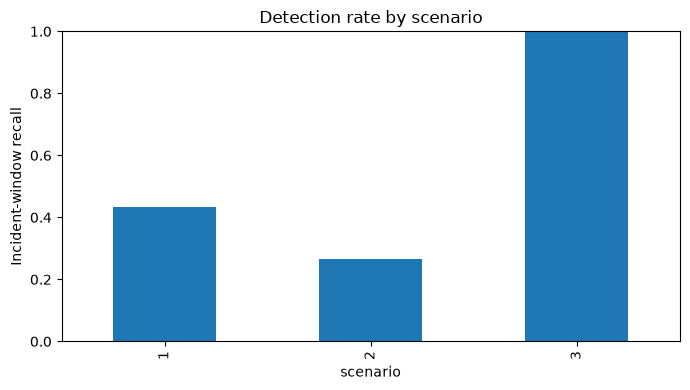

In [11]:
incidents.groupby("scenario")["detected"].mean().plot(kind="bar", ylim=(0, 1), figsize=(7, 4))
plt.ylabel("Incident-window recall")
plt.title("Detection rate by scenario")
plt.tight_layout()
plt.show()